<a href="https://colab.research.google.com/github/replyeshab/CineAI-AI-Based-Hybrid-Recommendation-System/blob/main/CineAI_v2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CineAI v2

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
!pip -q install implicit lightgbm shap fastapi uvicorn
from google.colab import drive; drive.mount("/content/drive")
import sys; ROOT = "/content/drive/MyDrive/CineAI/Notebooks"; sys.path.insert(0, ROOT + "/code")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 42.7 MB/s eta 0:00:00
Mounted at /content/drive


## 1 · Data → leak-free temporal split
Per user: oldest 75 % = train, next 10 % = val, newest 15 % = test (the model never sees the future).

In [2]:
import gc, numpy as np, pandas as pd, cineai as ca
DATA = "/content/drive/MyDrive/CineAI/ml-32m/ml-32m"; ART = "/content/drive/MyDrive/CineAI/Artifact"; os.makedirs(ART, exist_ok=True)
ratings = ca.load_ratings("/content/drive/MyDrive/CineAI/ml-32m/ml-32m/ratings.csv")                      # int32/float32 -> ~0.5 GB instead of ~2 GB
movies  = pd.read_csv("/content/drive/MyDrive/CineAI/ml-32m/ml-32m/movies.csv")
tags = pd.read_csv("/content/drive/MyDrive/CineAI/ml-32m/ml-32m/tags.csv", usecols=["movieId", "tag"])    # user tags make the content model much better
item_text = tags.groupby("movieId")["tag"].apply(lambda s: " ".join(s.astype(str).str.lower().head(50)))

train, val, test = ca.temporal_split(ratings, val_frac=0.10, test_frac=0.15)
rs = ca.Recsys(movies)
uidx = pd.Index(np.sort(ratings.userId.unique()))
trc, vac, tec = (ca.to_csr(d, uidx, rs.midx) for d in (train, val, test))
del ratings, train, val, test, tags; gc.collect()
print("train/val/test ratings:", trc.nnz, vac.nnz, tec.nnz)

train/val/test ratings: 23925629 3179563 4895012


## 2 · Base models (ALS item factors + content embedding + statistics) — slowest step, checkpointed

In [3]:
BASE = ART + "/rs_base.pkl"
if os.path.exists(BASE): rs = ca.Recsys.load(BASE)
else:
    rs.fit_base(trc, item_text); rs.save(BASE)       # ~10-20 min on free CPU; set cfg als_iters=10 to go faster
print("item factors:", rs.VF.shape)

/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/15 [00:00<?, ?it/s]

item factors: (87585, 64)


## 3 · Ranker + taste model
Trained on **val-period labels** (never seen by ALS) with **randomly truncated histories** (1, 2, 3, 5, 8 … ratings), so the ranker learns how much to trust each signal for cold and warm users.
Lower `n_rank` (e.g. 8000) if you run short of time.

In [4]:
tr, es, used = ca.build_training_sets(rs, trc, vac, n_rank=15000, n_es=3000)
print("training rows:", tr.shape, "| share of rows that are real val ratings:", round((tr.rating > 0).mean(), 3))
rs.fit_rankers(tr, es); rs.save(ART + "/rs_full.pkl")

training rows: (2363166, 21) | share of rows that are real val ratings: 0.113
[50]	valid_0's ndcg@10: 0.442828
[100]	valid_0's ndcg@10: 0.449383
[150]	valid_0's ndcg@10: 0.454467
[200]	valid_0's ndcg@10: 0.454535
[250]	valid_0's ndcg@10: 0.45508
[300]	valid_0's ndcg@10: 0.455169
[50]	valid_0's auc: 0.80118
[100]	valid_0's auc: 0.803334
[150]	valid_0's auc: 0.803819


## 4 · Honest evaluation (test period only)
* **Protocol A – taste:** rank the movies a user *really rated later*; relevant = rating ≥ 4. Compare against the printed base rate (= precision of random guessing).
* **Protocol B – discovery:** rank the whole catalogue; relevant = a ≥ 4 rating in the test period. Absolute numbers here are low for *every* recommender; compare with the ALS / popularity rows.

In [5]:
rep = ca.evaluate(rs, trc, vac, tec, n_users=2000, exclude=used)
print("Random-guess precision (A):", round(rep["A_base_rate"], 3)); display(rep["A"].round(3))
print("Discovery (B):"); display(rep["B"].round(3)); print(rep["B_extra"])
print("Precision/coverage trade-off of the taste model:"); display(rep["curve"].round(3))
print("Threshold tuned on validation users for 80% precision ->", rep.get("conf80"))

Random-guess precision (A): 0.547


,P@10,Recall@10,NDCG@10,HitRate@10,users
LightGBM taste model,0.670,0.567,0.756,0.994,1978.0
ALS only,0.608,0.519,0.686,0.984,1978.0
user mean + item mean,0.659,0.557,0.743,0.990,1978.0
popularity,0.656,0.556,0.740,0.990,1978.0


Discovery (B):


,P@10,Recall@10,NDCG@10,HitRate@10,users
LightGBM ranker,0.070,0.054,0.077,0.448,1978.0
ALS only,0.101,0.073,0.115,0.541,1978.0
popularity,0.027,0.017,0.031,0.195,1978.0


{'coverage': 0.027150767825540902, 'novelty_bits': 10.720250129699707, 'genre_diversity': 0.7582849356354308}
Precision/coverage trade-off of the taste model:


,p_like>=,precision,share_kept
0,0.50,0.703,0.474
1,0.55,0.726,0.421
2,0.60,0.751,0.366
3,0.65,0.775,0.310
4,0.70,0.802,0.247
5,0.75,0.830,0.186
6,0.80,0.854,0.128
7,0.85,0.880,0.076
8,0.90,0.919,0.027
9,0.95,1.000,0.000


Threshold tuned on validation users for 80% precision -> {'threshold': 0.6988517713184761, 'test_precision': 0.8013683985460766, 'share_of_items_kept': 0.24855844604469482}


## 5 · Cold-start curve (users truncated to k ratings; ML-32M has no real cold users)

In [6]:
display(ca.evaluate_cold_start(rs, trc, vac, tec, ks=(0, 1, 3, 5, 10, 20), n_users=1000, exclude=used).round(3))

,B: P@10,A: P@10
ratings given,,
0,0.027,NaN
1,0.033,0.659
3,0.038,0.659
5,0.042,0.661
10,0.040,0.662
20,0.051,0.663


## 6 · Explainable AI
Exact TreeSHAP comes straight from LightGBM (`pred_contrib=True`), so serving needs no `shap` package.

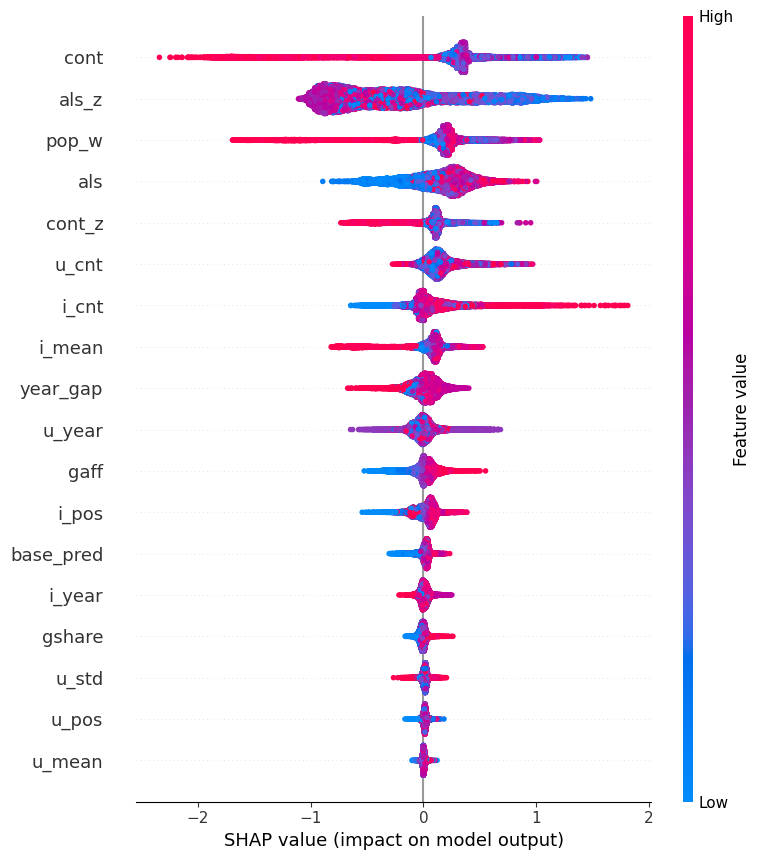

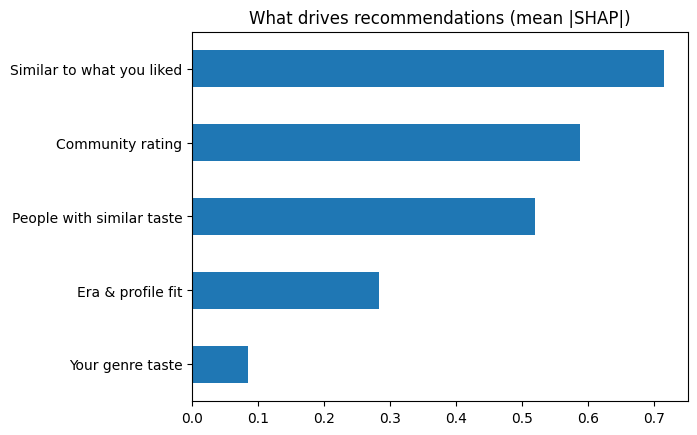

Dark Knight, The (2008)  match 91%  because of: {'movieId': 79132, 'title': 'Inception'}
   - Viewers whose ratings resemble yours loved it [People with similar taste +0.75]
   - Rated 4.2/5 by 51,327 viewers [Community rating +0.43]
   - Fits your taste for 2000s films [Era & profile fit +0.34]
Interstellar (2014)  match 90%  because of: {'movieId': 79132, 'title': 'Inception'}
   - Rated 4.2/5 by 30,497 viewers [Community rating +0.69]
   - Close in style to movies you rated highly [Similar to what you liked +0.38]
   - You tend to rate Sci-Fi & IMAX films highly [Your genre taste +0.15]
Up (2009)  match 84%  because of: {'movieId': 1, 'title': 'Toy Story'}
   - Rated 4.0/5 by 29,778 viewers [Community rating +0.63]
   - Close in style to movies you rated highly [Similar to what you liked +0.36]
   - Fits your taste for 2000s films [Era & profile fit +0.23]
Fight Club (1999)  match 91%  because of: {'movieId': 79132, 'title': 'Inception'}
   - Viewers whose ratings resemble yours lov

In [7]:
import matplotlib.pyplot as plt, shap
X = es.sample(min(20000, len(es)), random_state=0)
c, _ = rs.contributions(X)
shap.summary_plot(c, X[ca.FEATS], show=True)
g = pd.DataFrame(rs.grouped(c)).abs().mean().sort_values(); g.plot.barh(title="What drives recommendations (mean |SHAP|)"); plt.show()

def mid_of(t): return int(rs.movies.loc[rs.movies.clean_title.str.contains(t, regex=False), "movieId"].iloc[0])
demo_hist = [(mid_of("Matrix, The"), 5), (mid_of("Inception"), 5), (mid_of("Toy Story"), 4)]   # edit to taste
for r in rs.recommend(demo_hist, top_n=5):
    print(f"{r['title']} ({r['year']})  match {r['match']}%  because of: {r['because']}")
    for x in r["reasons"]: print("   -", x["text"], f"[{x['group']} {x['impact']:+.2f}]")

## 7 · Serve it to your webpage
Starts the API in this notebook and opens a free public tunnel (no account needed). Paste the printed URL into `API_URL` in `cineai_widget.html`.

In [10]:
import threading, subprocess, re, time, uvicorn
from app import create_app
api = create_app(rs)                                                   # restrict origins=["https://yoursite.com"] in production
threading.Thread(target=lambda: uvicorn.run(api, host="0.0.0.0", port=8000, log_level="warning"), daemon=True).start()
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared && chmod +x /content/cloudflared
p = subprocess.Popen(["/content/cloudflared", "tunnel", "--url", "http://localhost:8000"], stderr=subprocess.PIPE, text=True)
for line in p.stderr:
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", line)
    if m: print("API_URL =", m.group(0)); break

ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use


/content/cloudflared: Text file busy
API_URL = https://bodies-quarterly-polymer-tide.trycloudflare.com
